<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Hysteresis_Loop_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

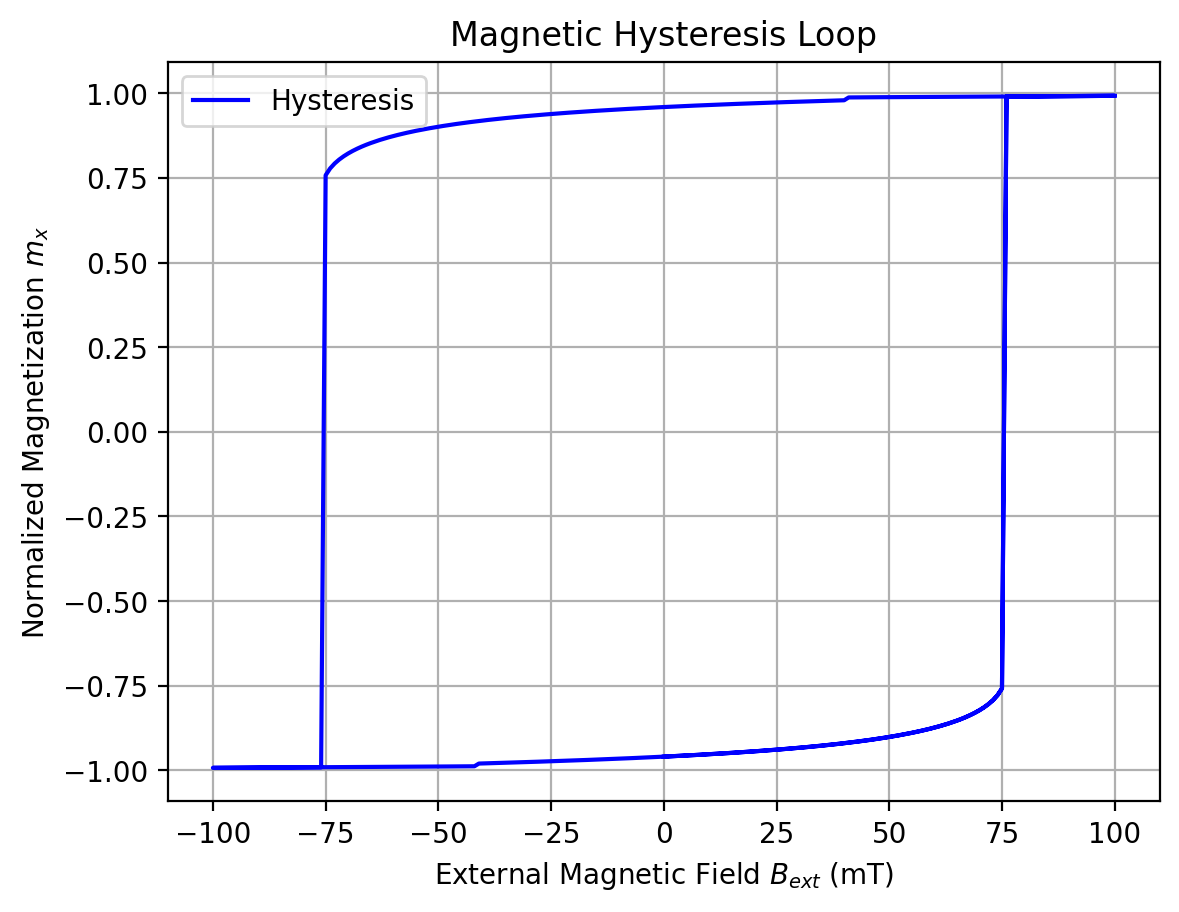

In [7]:
"""This script calculates the magnetic hysteresis loop using mumaxplus.
"""

import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World

plt.rcParams['figure.dpi'] = 200

# CONTROL KNOBS
msat_val = 800e3
aex_val = 13e-12
alpha_val = 0.5  # High damping promotes rapid energy dissipation during relaxation
b_max_val = 100.0e-3
b_step_val = 1.0e-3
nx_val = 128
ny_val = 32
nz_val = 1
cell_x = 4e-9
cell_y = 4e-9
cell_z = 30e-9

# DOMAIN SPECIFICATIONS
world = World(cellsize=(cell_x, cell_y, cell_z))
grid = Grid((nx_val, ny_val, nz_val))

# FERROMAGNET INITIALIZATION
magnet = Ferromagnet(world, grid)
magnet.msat = msat_val
magnet.aex = aex_val
magnet.alpha = alpha_val

random_field = np.random.uniform(-1.0, 1.0, (3, nz_val, ny_val, nx_val))
magnet.magnetization = random_field

magnet.relax()

# HYSTERESIS FIELD SWEEP
sweep_up_initial = np.arange(0.0, b_max_val + (b_step_val * 0.5), b_step_val)
sweep_down = np.arange(b_max_val - b_step_val, -b_max_val - (b_step_val * 0.5), -b_step_val)
sweep_up_final = np.arange(-b_max_val + b_step_val, b_max_val + (b_step_val * 0.5), b_step_val)

b_array = np.concatenate((sweep_up_initial, sweep_down, sweep_up_final))

bias_list = []
mx_list = []

for b_ext in b_array:
    world.bias_magnetic_field = (b_ext, 0.0, 0.0)
    magnet.minimize()

    bias_list.append(b_ext)
    mx_list.append(magnet.magnetization.average()[0])

# VISUALIZATION RENDERING
plt.plot(
    np.array(bias_list) * 1e3,
    mx_list,
    color="#0000FF",
    linewidth=1.5,
    label="Hysteresis"
)
plt.xlabel("External Magnetic Field $B_{ext}$ (mT)")
plt.ylabel("Normalized Magnetization $m_x$")
plt.title("Magnetic Hysteresis Loop")
plt.grid(True)
plt.legend()
plt.show()